# Aula 04 — Inspeção Visual de Defeitos: pruning e quantização para produção industrial

**Disciplina: Engenharia de Machine Learning — FIAP PósTech**

---

## 🎯 Objetivo da aula

Nesta aula vamos entender, na prática, como **pruning** e **quantização** ajudam a **reduzir a latência**, o **tamanho do modelo** e o **custo computacional** de um sistema de visão computacional que precisa funcionar em **tempo real** em uma linha de produção.

Usaremos como exemplo o caso de uma **fábrica que inspeciona defeitos** nos produtos com deep learning. Ao final, você será capaz de:

1. Entender o problema de latência na inspeção visual em linha de produção.
2. Explicar de forma simples o que são **pruning** (estruturado/não-estruturado) e **quantização** (PTQ/QAT).
3. Medir na prática a latência média e calcular o throughput (FPS) de um pipeline de inferência.
4. Comparar um modelo **pesado** (ResNet-50) com uma versão **otimizada** (quantização PTQ).
5. Avaliar se o sistema atende à meta de produção de **30 itens por segundo**.
6. Discutir técnicas reais de otimização e seus trade-offs (velocidade × memória × acurácia).

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Geração de ruído e estatísticas |
| **Pandas** | 2.0+ | Tabela comparativa |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy`, `pandas` e `matplotlib`. **Não requer GPU**, internet ou datasets externos — roda em qualquer ambiente local simples.

### 2. Instalação das dependências

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 04_otimizacao_modelos_pruning_quantizacao
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy pandas matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.

In [1]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar as proximas celulas.
%pip install numpy pandas matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, pandas, matplotlib
    print("numpy:", numpy.__version__)
    print("pandas:", pandas.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy pandas matplotlib' acima e rode esta celula novamente.")

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.14
numpy: 2.5.0
pandas: 3.0.3
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


## 1. Introdução: a inspeção visual de defeitos na linha de produção

Imagine uma **fábrica** que usa deep learning para **detectar defeitos** nos produtos ao longo da **linha de produção**. Uma câmera fotografa cada item que passa na esteira e um modelo de IA decide se a peça está **OK** ou **defeituosa**, encaminhando as peças reprovadas para descarte ou retrabalho.

Hoje o sistema usa um modelo robusto de visão computacional baseado em **ResNet-50**, com **alta acurácia** na identificação de falhas.

### Características do cenário atual

| Item | Valor aproximado |
|---|---|
| Modelo | ResNet-50 |
| Parâmetros | ~25 milhões |
| Operações por imagem | ~4 bilhões |
| Latência média | ~200 ms por imagem |
| Throughput | ~5 itens/segundo |
| Hardware | industrial, limitado (sem GPU dedicada) |

### O problema

A linha de produção movimenta cerca de **30 itens por segundo**. Com **~200 ms por imagem**, o modelo consegue analisar apenas **~5 itens por segundo** — ou seja, ele **não acompanha a esteira**. Peças passariam sem inspeção, e defeitos chegariam ao cliente. Além disso, o **hardware industrial é limitado** e precisa de uma solução mais **leve** (menos memória e menos custo computacional).

### O objetivo de negócio

O sistema precisa processar imagens com **muito mais rapidez**, ou seja:

- Processar cada imagem em cerca de **33 ms** (para acompanhar ~30 itens/s).
- Reduzir a latência de inferência e aumentar o throughput.
- Deixar o modelo **mais leve**, para caber no hardware limitado.
- Manter acurácia **suficiente** para separar peças boas de defeituosas.

```
🏭 Esteira → [foto do item] → [modelo de IA] → [decisão: defeito?] → ✅ / ❌ descarte
```

> 🧩 A pergunta central da aula é: **o modelo consegue analisar cada peça rápido o suficiente para acompanhar a linha de produção?**

## 2. Conceitos principais

Antes do hands-on, alguns conceitos simples que amarram toda a aula. A ideia é entender **o que otimiza** o modelo — não decorar teoria.

### ✂️ Pruning (poda)

É **remover partes do modelo que pouco contribuem** para a decisão (pesos ou neurônios próximos de zero). Uma rede como a ResNet-50 tem milhões de pesos, e boa parte é quase irrelevante. Podando essas partes, o modelo fica **menor e mais rápido**, idealmente sem perder muita acurácia.

- **Pruning não-estruturado:** remove **pesos individuais** espalhados pela rede (deixa a matriz "esburacada"/esparsa). Comprime bastante, mas o ganho de velocidade depende de hardware/bibliotecas que aproveitem a esparsidade.
- **Pruning estruturado:** remove **blocos inteiros** (neurônios, canais ou filtros convolucionais). O modelo fica genuinamente **menor** e mais rápido em qualquer hardware — ótimo para o **hardware industrial limitado** da fábrica.

### 🔢 Quantização

É **reduzir a precisão numérica** dos pesos e ativações — por exemplo, trocar números de **32 bits (FP32)** por **inteiros de 8 bits (INT8)**. Menos bits significam **menos memória** e **contas mais rápidas**, deixando o modelo até **~4x menor**.

- **PTQ (Post-Training Quantization):** quantiza um modelo **já treinado**, sem re-treino. É **simples e rápido** de aplicar — ideal para começar.
- **QAT (Quantization-Aware Training):** simula a quantização **durante o treino**, para o modelo "aprender" a conviver com a baixa precisão. Custa mais tempo, mas costuma **recuperar acurácia** perdida na PTQ.

### 🧮 Por que modelos grandes costumam ser lentos?

Modelos como a ResNet-50 têm **muitos parâmetros** (~25 milhões) e fazem **bilhões de operações** por imagem. Mais operações = mais tempo de cálculo = **maior latência**. Pruning **reduz o número de operações**; quantização **reduz o custo de cada operação**. Juntos, atacam a latência por dois lados.

### 🏭 Por que otimizar é importante em produção industrial?

Na fábrica, o hardware é **limitado** e a esteira **não espera**. Um modelo menor e mais rápido significa **acompanhar a linha**, **caber no hardware disponível** e **reduzir custo** — sem precisar comprar GPUs caras.

## 3. Hands-on prático

Para manter tudo simples e sem GPU, vamos focar em **um** conceito no hands-on: a **quantização PTQ**. Vamos **simular** dois cenários de inferência e medir suas métricas.

Em vez de rodar uma CNN real (que exigiria GPU e pesos treinados), simulamos o **tempo de inferência** de cada imagem com `time.sleep()`. Assim o foco fica onde importa nesta aula: **medir latência, throughput e tamanho do modelo** antes e depois da otimização.

- **Cenário A — Modelo pesado:** ResNet-50 em FP32, ~**200 ms** por imagem.
- **Cenário B — Modelo otimizado:** mesma ResNet-50 após **quantização PTQ (INT8)**, ~**33 ms** por imagem e **~4x menor**.

> A quantização torna as contas mais baratas: por isso a latência cai. Como INT8 usa 8 bits no lugar de 32, o modelo também ocupa cerca de **1/4** do tamanho em disco/memória.

Primeiro, os imports e a função de simulação que os dois cenários vão reutilizar.

In [2]:
# ------------------------------------------------------------------
# IMPORTS - enxutos para manter o notebook leve e sem GPU
# ------------------------------------------------------------------
import time                       # medir o tempo (latencia/throughput)
import numpy as np                # gerar o 'jitter' (ruido) e estatisticas
import pandas as pd               # montar a tabela comparativa
import matplotlib.pyplot as plt   # visualizar os resultados

# Semente fixa -> resultados reproduziveis (todos veem numeros parecidos).
np.random.seed(42)

# Meta de negocio: a esteira movimenta ~30 itens por segundo.
# Para acompanhar, o modelo precisa processar >= 30 imagens por segundo.
META_ITENS_POR_S = 30
LATENCIA_ALVO_MS = 1000 / META_ITENS_POR_S   # ~33.3 ms por imagem para bater a meta

print(f"Meta de producao: {META_ITENS_POR_S} itens/s  (<= {LATENCIA_ALVO_MS:.1f} ms por imagem)")
print("Ambiente pronto.")

Meta de producao: 30 itens/s  (<= 33.3 ms por imagem)
Ambiente pronto.


In [3]:
# ==================================================================
# FUNCAO DE SIMULACAO - o coracao do experimento
# ==================================================================
# OBJETIVO: imitar (simular) um sistema de visao inspecionando itens da
# esteira, para conseguirmos MEDIR latencia e throughput (itens/segundo).
#
# POR QUE SIMULAR em vez de usar um modelo real?
#   - Uma ResNet-50 real precisaria de GPU, pesos treinados, imagens de
#     verdade e bibliotecas pesadas (PyTorch/TensorFlow).
#   - Nesta aula o foco NAO e a acuracia do modelo, e sim ENTENDER como
#     a otimizacao afeta as metricas de performance. Entao substituimos a
#     "inferencia real" por um time.sleep(): dormir X ms "finge" que o
#     modelo levou X ms para analisar aquela imagem. O relogio nao sabe a
#     diferenca. :)
#
# IDEIA CENTRAL: se cada imagem custa ~L milissegundos, quantas imagens
# cabem em 1 segundo? Essa e a pergunta que a funcao responde, medindo o
# tempo de verdade com o cronometro do computador.


def simular_inspecao(latencia_media_ms, n_itens=30, jitter_ms=5.0):
    """Inspeciona N itens (simulados) e devolve as metricas de performance.

    Parametros
    ----------
    latencia_media_ms : tempo MEDIO que "o modelo" leva por imagem (ms).
                        Ex.: 200 = modelo pesado; 33 = modelo otimizado.
    n_itens           : quantos itens da esteira inspecionar em sequencia.
                        Pense nisso como "quantas fotos a camera mandou".
    jitter_ms         : o quanto o tempo de cada imagem VARIA aleatoriamente.
                        No mundo real nenhuma imagem leva exatamente o mesmo
                        tempo (cache, sistema operacional, etc.). O jitter
                        adiciona essa variacao para ficar realista.

    Retorna
    -------
    dict com: n_itens, tempo_total_s, latencia_media_ms e itens_por_s.
    """
    # Lista onde vamos guardar a latencia REAL medida de cada imagem (em ms).
    # No fim, a media dessa lista e a "latencia media por imagem".
    latencias = []

    # ---- CRONOMETRO GERAL -------------------------------------------------
    # perf_counter() e um relogio de alta precisao (em segundos). Guardamos
    # o instante de INICIO do lote inteiro para, no final, saber quanto tempo
    # levou para inspecionar TODOS os itens -> isso vira o throughput.
    inicio_total = time.perf_counter()

    # ---- LOOP: inspeciona um item de cada vez -----------------------------
    # Um pipeline simples analisa os itens em sequencia (um apos o outro).
    for _ in range(n_itens):
        # 1) Sortear quanto ESTA imagem vai custar.
        #    np.random.normal(media, desvio) sorteia um numero em torno da
        #    latencia media. Ex.: media=200, jitter=8 -> normalmente entre
        #    ~184 e ~216 ms. Cada imagem fica um pouco diferente (realismo).
        #    max(0.0, ...) e uma trava de seguranca: tempo nunca e negativo.
        atraso_ms = max(0.0, latencia_media_ms + np.random.normal(0, jitter_ms))

        # 2) Cronometrar o "processamento" desta unica imagem.
        t0 = time.perf_counter()             # marca o inicio da imagem
        time.sleep(atraso_ms / 1000.0)       # DORME atraso_ms (÷1000: ms -> s)
        t1 = time.perf_counter()             # marca o fim da imagem
        # OBS: o time.sleep e o que "simula" o modelo trabalhando. Enquanto
        #      ele dorme, e como se a CPU estivesse calculando a resposta.

        # 3) Guardar a latencia REAL medida (t1 - t0), convertida de s para ms.
        #    Medimos o tempo de verdade (em vez de so confiar no atraso_ms)
        #    porque o sleep tem pequenas imprecisoes -> medir e mais honesto.
        latencias.append((t1 - t0) * 1000.0)

    # Instante de FIM do lote inteiro (todos os itens ja foram inspecionados).
    fim_total = time.perf_counter()

    # ---- CALCULO DAS METRICAS --------------------------------------------
    # tempo_total_s: quanto tempo (em segundos) levou para inspecionar tudo.
    tempo_total_s = fim_total - inicio_total

    # latencia_media_ms: media das latencias individuais -> "tempo tipico
    # por imagem". E o numero que comparamos com o alvo de ~33 ms.
    latencia_media = float(np.mean(latencias))

    # itens_por_s (throughput): a metrica-chave de produção.
    # Formula: total de itens dividido pelo tempo total gasto.
    # Ex.: 30 itens em 6 s -> 5 itens/s.  30 itens em 1 s -> 30 itens/s.
    itens_por_s = n_itens / tempo_total_s

    # Devolvemos tudo num dicionario para as proximas celulas usarem/comparar.
    return {
        "n_itens": n_itens,
        "tempo_total_s": tempo_total_s,
        "latencia_media_ms": latencia_media,
        "itens_por_s": itens_por_s,
    }


print("Funcao 'simular_inspecao' pronta para uso.")

Funcao 'simular_inspecao' pronta para uso.


### Cenário A — Modelo pesado (ResNet-50 em FP32)

Simulamos o sistema **atual**: cada imagem leva cerca de **200 ms** para ser processada. Vamos inspecionar 30 itens (como se fosse ~1 segundo de esteira a 30 itens/s) e medir o que realmente acontece.

In [4]:
# Cenario A - modelo pesado (ResNet-50 FP32): ~200 ms por imagem
res_a = simular_inspecao(latencia_media_ms=200, n_itens=30, jitter_ms=8)

# Tamanho relativo do modelo (referencia): FP32 = 100% (linha de base).
tamanho_a_pct = 100

print("=== Cenario A - Modelo pesado (ResNet-50 FP32) ===")
print(f"Itens inspecionados : {res_a['n_itens']}")
print(f"Tempo total         : {res_a['tempo_total_s']:.2f} s")
print(f"Latencia media      : {res_a['latencia_media_ms']:.1f} ms/imagem")
print(f"Throughput          : {res_a['itens_por_s']:.1f} itens/s")
print(f"Tamanho do modelo   : {tamanho_a_pct}% (linha de base FP32)")

atende_a = res_a['itens_por_s'] >= META_ITENS_POR_S
print(f"Atinge {META_ITENS_POR_S} itens/s (meta)? -> {'SIM' if atende_a else 'NAO'}")

=== Cenario A - Modelo pesado (ResNet-50 FP32) ===
Itens inspecionados : 30
Tempo total         : 5.98 s
Latencia media      : 199.2 ms/imagem
Throughput          : 5.0 itens/s
Tamanho do modelo   : 100% (linha de base FP32)
Atinge 30 itens/s (meta)? -> NAO


Como esperado, com ~200 ms por imagem o sistema fica **muito abaixo** dos 30 itens/s (fica em torno de 5 itens/s). Na prática, a **esteira anda mais rápido do que o modelo consegue inspecionar**: peças passariam sem verificação.

### Cenário B — Modelo otimizado (ResNet-50 + quantização PTQ INT8)

Agora simulamos a versão **otimizada** do sistema: aplicamos **quantização PTQ (INT8)** ao mesmo modelo já treinado, sem re-treino. As contas ficam mais baratas (8 bits no lugar de 32), chegando a cerca de **33 ms por imagem**, e o modelo passa a ocupar cerca de **1/4** do tamanho original. Rodamos os **mesmos 30 itens** para comparar de forma justa.

In [5]:
# Cenario B - modelo otimizado (ResNet-50 + PTQ INT8): ~33 ms por imagem
res_b = simular_inspecao(latencia_media_ms=33, n_itens=30, jitter_ms=4)

# Tamanho relativo do modelo: INT8 usa 8 bits no lugar de 32 -> ~1/4 = 25%.
tamanho_b_pct = 25

print("=== Cenario B - Modelo otimizado (ResNet-50 + PTQ INT8) ===")
print(f"Itens inspecionados : {res_b['n_itens']}")
print(f"Tempo total         : {res_b['tempo_total_s']:.2f} s")
print(f"Latencia media      : {res_b['latencia_media_ms']:.1f} ms/imagem")
print(f"Throughput          : {res_b['itens_por_s']:.1f} itens/s")
print(f"Tamanho do modelo   : {tamanho_b_pct}% (~4x menor que FP32)")

atende_b = res_b['itens_por_s'] >= META_ITENS_POR_S
print(f"Atinge {META_ITENS_POR_S} itens/s (meta)? -> {'SIM' if atende_b else 'NAO'}")

# Quanto mais rapido ficou o sistema otimizado em relacao ao pesado?
ganho = res_b['itens_por_s'] / res_a['itens_por_s']
print(f"\nO sistema otimizado ficou ~{ganho:.1f}x mais rapido que o original.")

=== Cenario B - Modelo otimizado (ResNet-50 + PTQ INT8) ===
Itens inspecionados : 30
Tempo total         : 0.99 s
Latencia media      : 32.9 ms/imagem
Throughput          : 30.4 itens/s
Tamanho do modelo   : 25% (~4x menor que FP32)
Atinge 30 itens/s (meta)? -> SIM

O sistema otimizado ficou ~6.1x mais rapido que o original.


## 4. Comparação dos resultados

Vamos consolidar os dois cenários em uma **tabela** e, em seguida, em um **gráfico** para visualizar a diferença de latência, throughput e tamanho do modelo.

In [6]:
# Tabela comparativa dos dois cenarios
tabela = pd.DataFrame([
    {
        "Cenario": "A - ResNet-50 (FP32, pesado)",
        "Latencia media (ms)": round(res_a["latencia_media_ms"], 1),
        "Throughput (itens/s)": round(res_a["itens_por_s"], 1),
        "Tamanho relativo": f"{tamanho_a_pct}%",
        "Atende 30 itens/s?": "Sim" if res_a["itens_por_s"] >= META_ITENS_POR_S else "Nao",
    },
    {
        "Cenario": "B - ResNet-50 (PTQ INT8, otimizado)",
        "Latencia media (ms)": round(res_b["latencia_media_ms"], 1),
        "Throughput (itens/s)": round(res_b["itens_por_s"], 1),
        "Tamanho relativo": f"{tamanho_b_pct}%",
        "Atende 30 itens/s?": "Sim" if res_b["itens_por_s"] >= META_ITENS_POR_S else "Nao",
    },
])
tabela

,Cenario,Latencia media (ms),Throughput (itens/s),Tamanho relativo,Atende 30 itens/s?
0,"A - ResNet-50 (FP32, pesado)",199.2,5.0,100%,Nao
1,"B - ResNet-50 (PTQ INT8, otimizado)",32.9,30.4,25%,Sim


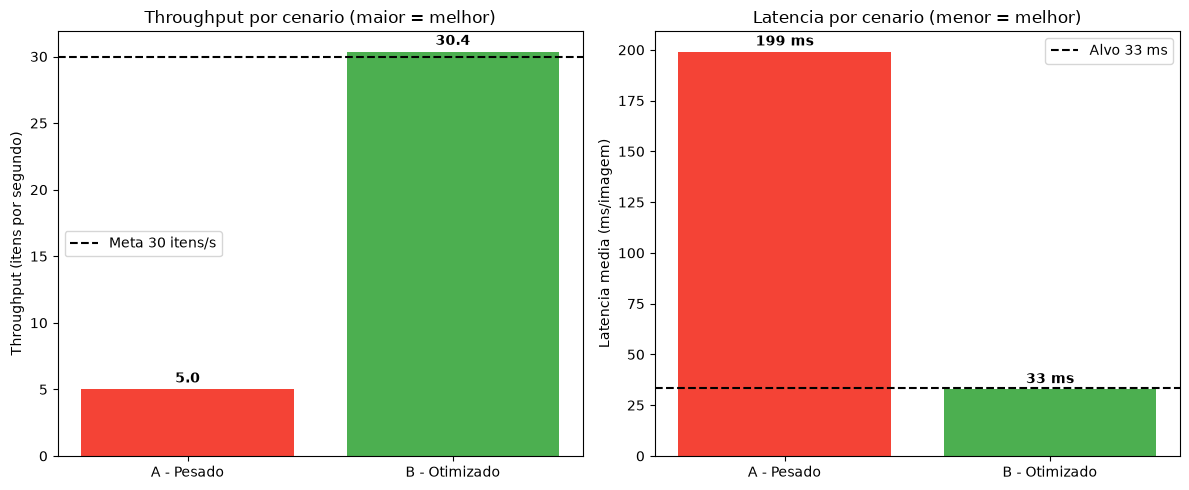

In [7]:
# Grafico comparativo: Throughput e Latencia lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cenarios = ["A - Pesado", "B - Otimizado"]
tput_vals = [res_a["itens_por_s"], res_b["itens_por_s"]]
lat_vals = [res_a["latencia_media_ms"], res_b["latencia_media_ms"]]
cores = ["#F44336", "#4CAF50"]  # vermelho = ruim, verde = bom

# Grafico 1: Throughput (quanto MAIOR, melhor). Linha tracejada = meta de 30 itens/s.
axes[0].bar(cenarios, tput_vals, color=cores)
axes[0].axhline(META_ITENS_POR_S, color="black", linestyle="--", label=f"Meta {META_ITENS_POR_S} itens/s")
axes[0].set_ylabel("Throughput (itens por segundo)")
axes[0].set_title("Throughput por cenario (maior = melhor)")
axes[0].legend()
for i, v in enumerate(tput_vals):
    axes[0].text(i, v + 0.5, f"{v:.1f}", ha="center", fontweight="bold")

# Grafico 2: Latencia (quanto MENOR, melhor). Linha tracejada = alvo ~33 ms.
axes[1].bar(cenarios, lat_vals, color=cores)
axes[1].axhline(LATENCIA_ALVO_MS, color="black", linestyle="--", label=f"Alvo {LATENCIA_ALVO_MS:.0f} ms")
axes[1].set_ylabel("Latencia media (ms/imagem)")
axes[1].set_title("Latencia por cenario (menor = melhor)")
axes[1].legend()
for i, v in enumerate(lat_vals):
    axes[1].text(i, v + 3, f"{v:.0f} ms", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Discussão técnica: como otimizar de verdade?

Na simulação "apenas trocamos o número" da latência e do tamanho. No mundo real, essa redução vem de técnicas concretas. Você **não precisa implementar todas** — basta entender como cada uma ajudaria o sistema de inspeção da fábrica:

| Técnica | Ideia central | Como ajuda a fábrica |
|---|---|---|
| **Pruning estruturado** | Remover canais/filtros inteiros | Modelo menor e mais rápido em qualquer hardware |
| **Pruning não-estruturado** | Zerar pesos individuais pouco relevantes | Alta compressão; ganho depende do hardware |
| **Quantização PTQ** | FP32 → INT8 sem re-treino | Rápido de aplicar; ~4x menor e mais veloz |
| **Quantização QAT** | Simular INT8 durante o treino | Recupera acurácia perdida na PTQ |
| **Fine-tuning após poda** | Re-treinar após remover pesos | Recupera acurácia perdida no pruning |
| **Aceleração por hardware** | Usar NPU/GPU/runtimes otimizados | Mais operações por segundo |
| **Redução de precisão numérica** | INT8 / FP16 no lugar de FP32 | Menos memória e cálculo por operação |

> 💡 Na prática, combina-se várias técnicas. Um caminho comum na indústria é: **pruning estruturado → fine-tuning → quantização PTQ (ou QAT)**. Cada etapa contribui com uma parte da aceleração e da compressão.

### ⚖️ Trade-offs entre velocidade, memória e acurácia

Toda otimização é um **equilíbrio**. Podar demais ou quantizar de forma agressiva reduz muito a latência e o tamanho, mas pode **derrubar a acurácia** — e um modelo rápido que deixa passar defeitos não serve. O objetivo é achar o ponto em que o modelo fica **rápido e leve o bastante** para o hardware e a esteira, **mantendo acurácia suficiente** para separar peças boas de defeituosas.

## 6. Conclusão

Respondendo às perguntas centrais da aula:

**1. O sistema original atende ao requisito de 30 itens/s?**
❌ **Não.** Com ~200 ms por imagem, a ResNet-50 em FP32 entrega cerca de **5 itens/s** — muito abaixo da meta. A esteira anda mais rápido do que o modelo inspeciona.

**2. O sistema otimizado atende ao requisito?**
✅ **Sim.** Com ~33 ms por imagem, o modelo quantizado (PTQ INT8) alcança cerca de **30 itens/s**, cumprindo o requisito de produção — e ainda ocupa **~4x menos** memória, cabendo no hardware industrial limitado.

**3. Qual é o impacto da otimização na linha de produção?**
A inspeção passa a **acompanhar a esteira**: todos os itens são analisados em tempo real, defeitos são barrados antes de chegar ao cliente e a solução roda em hardware **mais barato**, reduzindo custo operacional.

**4. Quais trade-offs existem entre velocidade, compressão e precisão?**
Pruning e quantização podem custar um pouco de **acurácia**. O segredo é garantir que a precisão continue **suficiente** para a tarefa (separar peças boas de defeituosas), muitas vezes recuperando parte dela com **fine-tuning** (após poda) ou **QAT** (na quantização). É sempre um equilíbrio entre **velocidade**, **memória/custo de hardware** e **qualidade da detecção**.

### 📌 Principais aprendizados

1. **Latência** é o tempo por imagem; **throughput** é quantas imagens por segundo.
2. Para pipelines simples: `throughput ≈ 1000 / latência_ms`.
3. Produção em tempo real na esteira exige acompanhar **~30 itens/s** (≤ 33 ms por imagem).
4. **Pruning** reduz o número de operações; **quantização** reduz o custo de cada operação — juntos atacam a latência e o tamanho.
5. Medir é essencial: só comparando cenários sabemos se a solução atende ao negócio.

### 🚀 Próximos passos sugeridos

- Variar `n_itens` e a latência alvo e observar o efeito no throughput.
- Simular um terceiro cenário intermediário (ex.: ~100 ms, apenas pruning) e ver se atende.
- Explorar, em um próximo módulo, pruning e quantização em um modelo **real** com PyTorch.

---

*Material da Aula 04 — Engenharia de Machine Learning — FIAP PosTech.*